# 21 — Beyond points per game: are our rules really about scoring?

**In brief**
- **Question:** charts use points per game because every reader knows it. But several of our rules are *defined* on points alone. Would an all-round measure (game score, usage) do the same job better?
- **Answer:** for the turning point (D27), only a little. In the live race a turning point on **game score** beat points by the rule written in advance (2 of 3 points of the season), so the live race now uses it (D41); before the season, points stayed. Points and game score are nearly the same measure for established players (correlation 0.955): voters discount *established* players, however that standing was earned. An elite level also counts against a candidate now (D42): a baseline game score of 16+ and last season in our star tier, which together sharpened the strict test by about 6%. "A 20-point scorer left" stays on points (D43): that rule really is about scoring.
- **Decisions** ([decision log](../docs/DECISIONS.md)): D41 (21B), D42 (21C–21D) and D43 (21E). Later sections will test D33 and the notebook 18 lookalikes.
- **Where it fits:** Phase B of the plan (TODO). It checks the Most Improved models (11, 12) rather than adding a new one.
- **Dated:** 21A–21E written 12 November 2026; further sections to follow.

**In detail.** Phase B has five steps: an inventory of what every model and rule uses (21A); all-round versions of the four points-defined rules (21B onwards, one rule at a time); more metrics in the models; plain captions; and decisions. This notebook starts with the inventory and the **scoring turning point** (D27), because it sits in both Most Improved models and carries one of the largest weights.

## 21A — What every model and rule uses (B1)

| Part of the project | Inputs | Role of points per game |
|---|---|---|
| **Live race** (in-season Most Improved, notebook 12) | Changes in points, rebounds, assists, steals, blocks, minutes, game score and true shooting; relative change in points and game score; team's change in winning; age; second year; baseline points (with the turning point); already an All-Star; back from a lost season | One input of 17, but with the largest weight |
| **Preseason Most Improved** (notebook 11) | Last season's minutes, points, usage and team wins; age, second year, new team; last season's trend and finish; preseason production, shot volume and shooting per 36; the turning point; a 20-point scorer left; already an All-Star; back from a lost season | One input of 16 |
| **Breakout models** (notebook 06) | 197 features: level, trend and change of every box-score, shooting, style and role measure, career and draft information | One of many |
| **Star score** (notebook 05) | Six equal pillars: scoring, creation, rebounding, defence, impact, trust | One pillar of six |
| **Playing-style clusters** (notebook 13) | 15 style measures | Not used, by design |
| **Unicorn scores** (notebook 04) | Rarity of skill combinations and distance to similar players, from style and body measures | Not used |
| **Scoring turning point** (D27) | Last season's points above 20 | **The definition**: tested in 21B |
| **"A 20-point scorer left"** (D29) | The departed player's points | **The definition** |
| **The blip test and leaps** (D33, notebook 16) | Share of the points jump kept | **The definition** (kept on points for Alexander-Walker, as written in advance) |
| **Ty Jerome lookalikes** (notebook 18) | Up 8+ points at day 19 | **The definition** |

The models already use many measures. The **rules that shape them** are where points stand alone, so those are tested one at a time.

The cell below prints each Most Improved model's inputs straight from the code, so this table cannot drift from what is actually used.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from unicorn import mip_history as MH
from unicorn.allstars import add_prior_allstar, load_selections
from unicorn.hot_start import add_stale
from unicorn.labels import MIP_WINNERS
from unicorn.mip_eval import LIVE_INPUTS, POINTS_INPUTS, current_frame, scorecard, turning_point_ranks
from unicorn.plotting import FIG_DIR, INK, INK2, MUTED, SERIES, SURFACE, apply_style
from unicorn.preseason import USED, TURN, add_pool_flags, add_star_left, add_turning_point, load_preseason, preseason_frame
from unicorn.raw import PROJECT_ROOT

warnings.filterwarnings("ignore")
apply_style()
sel = load_selections()
print("live race inputs:", LIVE_INPUTS)
print("preseason inputs:", USED)

live race inputs: ['ppg_delta', 'rpg_delta', 'apg_delta', 'mpg_delta', 'game_score_delta', 'ts_delta', 'spg_delta', 'bpg_delta', 'ppg_rel', 'game_score_rel', 'team_win_delta', 'age', 'second_year', 'base_game_score', 'over_turn', 'prior_allstar', 'stale', 'elite_level', 'base_star_tier']
preseason inputs: ['mpg_last', 'ppg_last', 'usg_last', 'team_win_pct_last', 'age', 'second_year', 'new_team', 'momentum_game_score', 'late_surge_last', 'pre_game_score_change', 'pre_volume_change', 'pre_ts_change', 'ppg_over_turn', 'star_left', 'prior_allstar', 'stale']


## 21B — The scoring turning point: points, game score or usage? (D27)

**The rule today.** Last season's scoring counts *for* a candidate up to 20 points a game and *against* him above it: established scorers are MVP material, not Most Improved. No winner since 2000-01 had scored more than 20.3 the season before.

**The question.** Is it really *scoring* that voters hold against established players, or being an established, all-round high-level player? If the second, a turning point on **game score** (all-round production) or **usage** (share of the offence) should fit better.

**Variants** (the measure gets both the straight input and the turning point, unless marked "turning point only"):

| Model | Variant | Straight input | Turning point on |
|---|---|---|---|
| In-season | **points** (current) | baseline points | baseline points |
| In-season | game score | baseline game score | baseline game score |
| In-season | game score, turning point only | baseline points | baseline game score |
| Preseason | **points** (current) | last season's points | last season's points |
| Preseason | game score | last season's game score | last season's game score |
| Preseason | game score, turning point only | last season's points | last season's game score |
| Preseason | usage | last season's usage (already an input) | last season's usage |
| Preseason | usage, turning point only | last season's points | last season's usage |

Usage is only tested before the season: the game logs behind the in-season model have no usage.

**A fair contest.** Each measure gets a grid of five turning points placed at the **same percentiles of candidates** as 16–24 points (game score 12.5–18.5; usage 23.5–29%), plus "no turning point". The turning point is **chosen inside each training set** by season-grouped cross-validation, as the live race does (D32), so no variant is tuned on the season it is tested on.

**The rule for deciding, written before the results:** a measure replaces points only if it improves × a blind guess in the **strict** test at most of the points tested, without lowering how often the winner is in our top 7. Ties keep points.

In [2]:
# in-season: every past season (2000-01 → 2025-26) at day 19, day 85 and the end of the season
g = MH.load_games(); info = MH.player_info(); votes, winners = MH.voting(g)
POINTS_OF_SEASON = {"day 19": 19, "day 85": 85, "end of season": None}
INS = {k: current_frame(g, info, winners, sel, day=d, turn=None) for k, d in POINTS_OF_SEASON.items()}

# preseason: 2012-13 → 2025-26 (preseason game logs start in 2012-13)
regular = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "player_games.parquet")
ps = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "player_season.parquet")
pre = load_preseason(regular=regular, refresh_latest=False)
F = add_stale(add_prior_allstar(add_star_left(add_turning_point(add_pool_flags(preseason_frame(pre, regular, ps), MIP_WINNERS)), pre, regular), sel))
PRE = F[F["season"] != "2026-27"].reset_index(drop=True)

GRID = {"points": (None, 16, 18, 20, 22, 24), "game score": (None, 12.5, 14, 15.5, 17, 18.5), "usage": (None, 0.235, 0.25, 0.265, 0.28, 0.29)}
BASE_IN = [c for c in POINTS_INPUTS if c not in ("base_ppg", "over_turn")]   # the model without its scoring level, as it stood before this test
BASE_PRE = [c for c in USED if c not in TURN + ["ppg_last"]]
IN_VARIANTS = {   # name: (inputs without the turning point, turning point on, grid)
    "points (current)": (BASE_IN + ["base_ppg"], "base_ppg", GRID["points"]),
    "game score": (BASE_IN + ["base_game_score"], "base_game_score", GRID["game score"]),
    "game score, turning point only": (BASE_IN + ["base_ppg"], "base_game_score", GRID["game score"]),
}
PRE_VARIANTS = {
    "points (current)": (BASE_PRE + ["ppg_last"], "ppg_last", GRID["points"]),
    "game score": (BASE_PRE + ["gspg_last"], "gspg_last", GRID["game score"]),
    "game score, turning point only": (BASE_PRE + ["ppg_last"], "gspg_last", GRID["game score"]),
    "usage": (BASE_PRE, "usg_last", GRID["usage"]),
    "usage, turning point only": (BASE_PRE + ["ppg_last"], "usg_last", GRID["usage"]),
}
print({k: f"{len(v):,} candidates, {v['season'].nunique()} seasons" for k, v in INS.items()})
print(f"preseason: {len(PRE):,} candidates, {PRE['season'].nunique()} seasons")

{'day 19': '7,057 candidates, 26 seasons', 'day 85': '7,331 candidates, 26 seasons', 'end of season': '7,509 candidates, 26 seasons'}
preseason: 5,230 candidates, 14 seasons


In [3]:
# run every variant in both tests; the turning point is chosen inside each training set
rows = []
def run(model, point, frame, variants):
    for name, (feats, level, grid) in variants.items():
        for scheme in ["strict", "leave-one-out"]:
            r = turning_point_ranks(frame, feats, level, grid, scheme=scheme)
            k = r["k"].astype(object).where(r["k"].notna(), "none").value_counts()
            rows.append({"model": model, "point": point, "variant": name, "test": scheme, **scorecard(r),
                         "turning point chosen (most often)": f"{k.index[0]} ({k.iloc[0]} of {len(r)})"})
for point, frame in INS.items():
    run("in-season", point, frame, IN_VARIANTS)
run("preseason", "before the season", PRE, PRE_VARIANTS)
R = pd.DataFrame(rows)
SHOW = ["× a blind guess", "in top 7", "median rank", "winner #1", "turning point chosen (most often)"]
for test in ["strict", "leave-one-out"]:
    print(test.upper())
    display(R[R["test"] == test].set_index(["model", "point", "variant"])[["seasons"] + SHOW]
            .style.format({"× a blind guess": "{:.1f}", "median rank": "{:.0f}"}))

STRICT


LEAVE-ONE-OUT


In [4]:
# the decision rule, applied: does any variant beat points in the strict test at most points, without fewer winners in the top 7?
strict = R[R["test"] == "strict"].set_index(["model", "point", "variant"])
verdict = []
for model, variants in [("in-season", IN_VARIANTS), ("preseason", PRE_VARIANTS)]:
    pts = strict.xs((model, "points (current)"), level=["model", "variant"])
    for name in variants:
        if name == "points (current)":
            continue
        v = strict.xs((model, name), level=["model", "variant"])
        better = (v["× a blind guess"] > pts["× a blind guess"]) & (v["in top 7"] >= pts["in top 7"])
        verdict.append({"model": model, "variant": name, "points of the season tested": len(v),
                        "better than points (strict, no fewer in top 7)": int(better.sum()),
                        "replaces points?": "yes" if better.sum() > len(v) / 2 else "no"})
pd.DataFrame(verdict).style.hide(axis="index")

model,variant,points of the season tested,"better than points (strict, no fewer in top 7)",replaces points?
in-season,game score,3,2,yes
in-season,"game score, turning point only",3,1,no
preseason,game score,1,0,no
preseason,"game score, turning point only",1,0,no
preseason,usage,1,0,no
preseason,"usage, turning point only",1,0,no


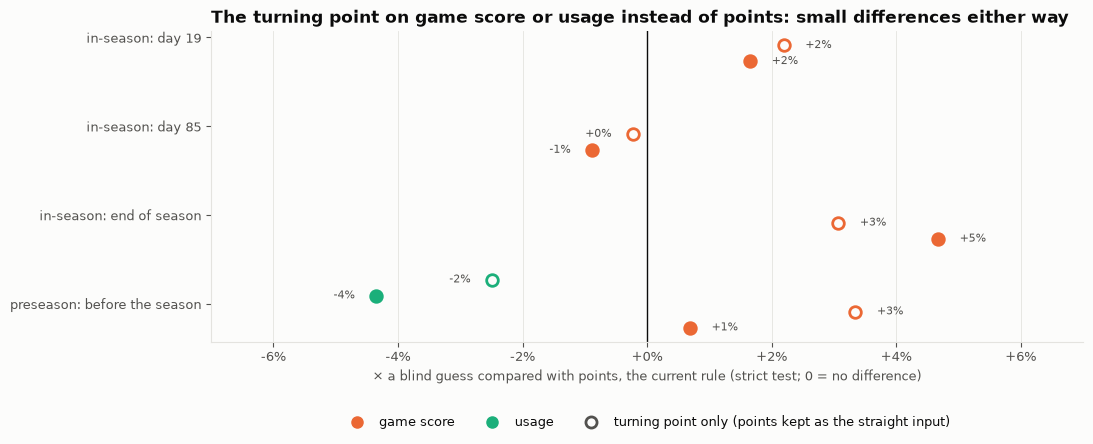

In [5]:
# chart: each variant against points (the current rule), strict test, on one shared scale
COL = {"points": SERIES[0], "game score": SERIES[1], "usage": SERIES[2]}
s = R[R["test"] == "strict"].copy()
s["family"] = s["variant"].str.extract(r"^(points|game score|usage)")[0]
s["only"] = s["variant"].str.contains("turning point only")
base = s[s["variant"] == "points (current)"].set_index(["model", "point"])["× a blind guess"]
s["vs points"] = s["× a blind guess"] / [base[(m, p)] for m, p in zip(s["model"], s["point"])] - 1
s = s[s["variant"] != "points (current)"]
order = [("in-season", "day 19"), ("in-season", "day 85"), ("in-season", "end of season"), ("preseason", "before the season")]
names = list(dict.fromkeys(s["variant"]))
fig, ax = plt.subplots(figsize=(11, 4.6))
ys = {o: len(order) - 1 - j for j, o in enumerate(order)}
offs = dict(zip(names, np.linspace(-0.27, 0.27, len(names))))
for _, r in s.iterrows():
    c = COL[r["family"]]; y = ys[(r["model"], r["point"])] + offs[r["variant"]]
    ax.scatter(r["vs points"] * 100, y, s=70, color=SURFACE if r["only"] else c, edgecolor=c, linewidth=2, zorder=3)
    ax.text(r["vs points"] * 100 + (0.35 if r["vs points"] >= 0 else -0.35), y, f"{round(r['vs points'] * 100):+d}%", va="center",
            ha="left" if r["vs points"] >= 0 else "right", fontsize=8, color=INK2)
ax.axvline(0, color=INK, linewidth=1)
ax.set_yticks(list(ys.values()), [f"{m}: {p}" for m, p in ys], fontsize=9.5)
lim = max(6, np.ceil(abs(s["vs points"]).max() * 100) + 2)
ax.set_xlim(-lim, lim); ax.xaxis.set_major_formatter(lambda v, _: f"{v:+.0f}%")
ax.set_xlabel("× a blind guess compared with points, the current rule (strict test; 0 = no difference)")
ax.grid(axis="y", visible=False)
ax.set_title("The turning point on game score or usage instead of points: small differences either way", loc="left", fontsize=12, fontweight="bold")
handles = [plt.Line2D([], [], marker="o", linestyle="", markersize=8, color=COL[k], label=k) for k in ("game score", "usage")]
handles += [plt.Line2D([], [], marker="o", linestyle="", markersize=8, markerfacecolor=SURFACE, markeredgecolor=INK2, markeredgewidth=2, label="turning point only (points kept as the straight input)")]
ax.legend(handles=handles, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "21_turning_point_measures.png", dpi=150, bbox_inches="tight")
plt.show()

### 21B findings (12 November 2026)

**1. By the rule written before the results, game score replaces points in the live race, and points stay before the season.**
- **In-season, strict test:** game score beat points at day 19 (6.3× → 6.4× a blind guess, the same 11 winners in the top 7) and at season's end (23.4× → 24.4×, the same 17), and lost narrowly at day 85 (19.4× → 19.2×, one fewer winner in the top 7). Two of three: it replaces points (**D41**).
- **The leave-one-out test agrees:** game score is level or better at every point (day 19 8.1× → 8.3×, with one more winner in the top 7; season's end 35.0× → 35.3×).
- **Before the season, nothing beat points** without losing a winner from the top 7. Usage was the weakest (5.7× → 5.4×).

**2. The differences are small, and that is the finding.** Every change is within ±5%. Baseline points and game score correlate at 0.955: for established players they are nearly the same measure. Voters discount players who are already *established*, whether that comes from scoring or from all-round production. The rule was never really a points crutch.

**3. Where the turning point sits.** The data chose game score 14 most often (about an 18-point scorer, at the same share of candidates), against 20 points before. No winner since 2000-01 had a baseline game score above 14.6.

**4. What it does not do.** In the live race, the straight input on the baseline game score and the turning point nearly cancel above 14: each extra point of baseline game score lowers the odds only slightly. So the turning point *neutralises* a star's high level rather than counting it against him, and an elite player with a big jump (Victor Wembanyama this season) can still rank highly. Since 2000-01, 75 candidates had a baseline game score of 22 or more; 5 got votes and none finished in the top 5. Testing an "already clearly a star" input is next (TODO, B2b).


## 21C — "Already clearly a star": should an elite level count against a candidate? (B2b)

**Why we're asking.** In the live race Victor Wembanyama is in the top 7 although he is already an All-Star (D38) and his baseline game score (22.4) is far above the turning point (D41). The turning point turns out to *neutralise* a high level rather than count it against a player: above game score 14, the straight input and the turning point nearly cancel (21B, finding 4). Since 2000-01, 75 candidates had a baseline game score of 22 or more; 5 got votes, none finished in the top 5, and no winner had a baseline game score above 14.6.

**Not a reason on its own:** that Wembanyama "looks too good to win" is a belief about the answer. An input is kept only if it improves the strict test across past seasons.

**Variants** (each added to the live race's model, with its turning point fixed at game score 14, D41):

| Variant | Input | Its threshold |
|---|---|---|
| a. Established-star flag | baseline game score at or above T (yes/no) | T from 16, 18, 20 or 22, chosen inside each training set |
| b. Second turning point | baseline game score above T (so the discount steepens for elite players) | the same |
| c. Star tier last season | baseline season in our star tier (top 10% by star score, notebook 05) | none. Star scores start in 2011-12, so this is tested on 2012-13 → 2025-26 only, against the current model on the same seasons |

**The rule for deciding, written before the results** (as in 21B): a variant is kept only if it improves × a blind guess in the **strict** test at most of the three points of the season (day 19, day 85, season's end), without lowering how often the winner is in our top 7. If more than one passes, the one with the larger average gain is kept; if they are level, the simpler (the flag).

**And a check in the style of D38:** under the current model, how many wins did players with a baseline game score of 18+ "deserve", against the 0 they got?

In [6]:
# 21C: frames with the live race's inputs (turning point fixed at game score 14) and the baseline season's star tier
from unicorn.labels import add_labels, add_star_score, STAR_TIER_PCTL
from unicorn.mip_eval import LIVE_INPUTS_D41, LIVE_TURN, tuned_input_ranks, winner_ranks   # the live race as it stood before this test (D41)
uni = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "player_season_unicorn.parquet")
stars = add_star_score(add_labels(uni))
stars = stars.assign(star_tier=(stars["star_pctl"].fillna(0) >= STAR_TIER_PCTL).astype(float)).set_index(["player_id", "season_start"])
CUR = {k: MH.with_turn(f, "base_game_score", LIVE_TURN) for k, f in INS.items()}
for k, f in CUR.items():
    key = list(zip(f["player_id"].astype(int), f["base_season_start"].astype(int)))
    f["base_star_tier"] = [stars["star_tier"].get(t, np.nan) for t in key]
    f["base_star_score"] = [stars["star_score"].get(t, np.nan) for t in key]
STAR_GRID = (16, 18, 20, 22)
B2B = {
    "a. established-star flag": lambda d, k: d.assign(extra=(d["base_game_score"] >= k).astype(float)),
    "b. second turning point": lambda d, k: d.assign(extra=(d["base_game_score"] - k).clip(lower=0)),
}
rows = []
for point, f in CUR.items():
    for scheme in ["strict", "leave-one-out"]:
        rows.append({"point": point, "test": scheme, "variant": "current model", **scorecard(winner_ranks(f, LIVE_INPUTS_D41, scheme=scheme))})
        for name, make in B2B.items():
            r = tuned_input_ranks(f, LIVE_INPUTS_D41, make, STAR_GRID, scheme=scheme)
            k = r["k"].value_counts()
            rows.append({"point": point, "test": scheme, "variant": name, **scorecard(r), "threshold chosen (most often)": f"{k.index[0]} ({k.iloc[0]} of {len(r)})"})
        # star tier: seasons whose baseline season has a star score (2012-13 on), against the current model on the same seasons
        sub = f[f["season_start"] >= 2012].reset_index(drop=True)
        rows.append({"point": point, "test": scheme, "variant": "current model, 2012-13 on", **scorecard(winner_ranks(sub, LIVE_INPUTS_D41, scheme=scheme))})
        rows.append({"point": point, "test": scheme, "variant": "c. star tier last season, 2012-13 on",
                     **scorecard(winner_ranks(sub.fillna({"base_star_tier": 0}), LIVE_INPUTS_D41 + ["base_star_tier"], scheme=scheme))})
B = pd.DataFrame(rows)
for test in ["strict", "leave-one-out"]:
    print(test.upper())
    display(B[B["test"] == test].set_index(["point", "variant"])[["seasons", "× a blind guess", "in top 7", "in top 3", "median rank", "winner #1", "threshold chosen (most often)"]]
            .style.format({"× a blind guess": "{:.1f}", "median rank": "{:.0f}"}, na_rep=""))

STRICT


LEAVE-ONE-OUT


In [7]:
# the decision rule, applied (strict test; the star tier is compared with the current model on the same seasons)
s = B[B["test"] == "strict"].set_index(["variant", "point"])
ref = {"a. established-star flag": "current model", "b. second turning point": "current model", "c. star tier last season, 2012-13 on": "current model, 2012-13 on"}
verdict = []
for name, base in ref.items():
    v, b = s.loc[name], s.loc[base]
    better = (v["× a blind guess"] > b["× a blind guess"]) & (v["in top 7"] >= b["in top 7"])
    gain = (v["× a blind guess"] / b["× a blind guess"] - 1).mean()
    verdict.append({"variant": name, "better at (of 3 points)": int(better.sum()), "average change in × a blind guess": f"{gain:+.1%}",
                    "passes the rule?": "yes" if better.sum() >= 2 else "no"})
pd.DataFrame(verdict).style.hide(axis="index")

variant,better at (of 3 points),average change in × a blind guess,passes the rule?
a. established-star flag,3,+2.1%,yes
b. second turning point,3,+0.6%,yes
"c. star tier last season, 2012-13 on",2,+2.4%,yes


In [8]:
# the D38-style check: under the current model (leave-one-out), how many wins did elite-baseline players "deserve"?
from unicorn.mip import ChoiceModel
ELITE = 18
chk = []
for point, f in CUR.items():
    probs = []
    for s_ in sorted(f["season"].unique()):
        te = f[f["season"] == s_]
        if te["mip"].any():
            p = ChoiceModel(LIVE_INPUTS_D41, MH.L2).fit(f[f["season"] != s_]).predict_proba(te)
            probs.append(te.assign(p=p))
    P = pd.concat(probs)
    e = P[P["base_game_score"] >= ELITE]
    per_season = e.groupby("season")["p"].sum()
    chk.append({"point": point, "elite candidates": len(e), "seasons": P["season"].nunique(), "expected wins": per_season.sum(),
                "actual wins": int(e["mip"].sum()), "chance of 0 wins if the model were right": float(np.prod(1 - per_season)),
                "highest single chance": f"{e['p'].max():.1%} ({e.loc[e['p'].idxmax(), 'player_name']}, {e.loc[e['p'].idxmax(), 'season']})"})
pd.DataFrame(chk).style.format({"expected wins": "{:.2f}", "chance of 0 wins if the model were right": "{:.0%}"}).hide(axis="index")

point,elite candidates,seasons,expected wins,actual wins,chance of 0 wins if the model were right,highest single chance
day 19,300,26,0.19,0,83%,"1.9% (Shai Gilgeous-Alexander, 2022-23)"
day 85,302,26,0.23,0,79%,"5.7% (Nikola Jokić, 2020-21)"
end of season,297,26,0.20,0,81%,"7.7% (Shai Gilgeous-Alexander, 2022-23)"


### 21C findings (12 November 2026)

**1. All three options pass the rule, by small margins** (strict test, × a blind guess, against the live race as it stood under D41):
- **a. Established-star flag:** better at all 3 points (day 19 6.6× → 6.7×; day 85 19.8× → 20.1×; season's end 24.9× → 25.5×; average +2.1%). The threshold chosen inside training was **16** in 62 of 63 windows.
- **b. Second turning point:** better at all 3 points, but only just (+0.6%).
- **c. Star tier last season** (9 strict seasons, 2012-13 on): better at 2 of 3 points (+2.4%), slightly worse at day 19.

**2. The history is thinner than it was for the All-Star input (D38).** Under the current model, players with a baseline game score of 18+ (about 300 candidates since 2000-01) were expected to win about 0.2 awards in total and won none, which the model would expect about 80% of the time. For D38 the model expected 2 to 2.5 wins from prior All-Stars and got none. So these inputs sharpen a model that already rarely picks elite players; they do not correct a large error.

**3. The rule's tie-break did not work.** It would have picked the star tier for its larger average gain, but that gain came from 9 seasons and the flag's from 21. So the options were compared again on the same seasons (21D), with a revised tie-break written before that test ran.


## 21D — A fair comparison: the flag, the star tier, or both? (B2b)

**Why this section exists.** In 21C all three options passed the rule. Its tie-break ("keep the larger average gain") would have picked the star tier, but the star tier was measured on 9 strict seasons and the flag on 21, so the two gains are not comparable. That tie-break was a flaw in the rule as written, so it is not used. Instead, every option is tested **on the same seasons** (2012-13 → 2025-26, when star scores exist), including both together.

**The rule for deciding, written before these results:** an option is kept only if it beats the current model in the strict test at 2 of the 3 points of the season without fewer winners in the top 7 (as before). If more than one passes, the larger average strict gain on these same seasons wins; if within 1 percentage point, the leave-one-out test decides; if still level, the simpler option.

**Both options are shown with their effect on today's board in the findings,** but the board plays no part in the decision.

In [9]:
# 21D: a fair comparison on the same seasons (2012-13 on, when star scores exist): the flag, the star tier, and both
SAME = {k: f[f["season_start"] >= 2012].fillna({"base_star_tier": 0}).reset_index(drop=True) for k, f in CUR.items()}
FLAG = B2B["a. established-star flag"]
D_VARIANTS = {
    "current model": ("plain", LIVE_INPUTS_D41),
    "a. flag (threshold chosen in training)": ("tuned", LIVE_INPUTS_D41),
    "c. star tier last season": ("plain", LIVE_INPUTS_D41 + ["base_star_tier"]),
    "a + c. both": ("tuned", LIVE_INPUTS_D41 + ["base_star_tier"]),
}
drows = []
for point, f in SAME.items():
    for scheme in ["strict", "leave-one-out"]:
        for name, (kind, feats) in D_VARIANTS.items():
            r = winner_ranks(f, feats, scheme=scheme) if kind == "plain" else tuned_input_ranks(f, feats, FLAG, STAR_GRID, scheme=scheme)
            extra = {}
            if kind == "tuned":
                k = r["k"].value_counts()
                extra = {"threshold chosen (most often)": f"{k.index[0]} ({k.iloc[0]} of {len(r)})"}
            drows.append({"point": point, "test": scheme, "variant": name, **scorecard(r), **extra})
D = pd.DataFrame(drows)
for test in ["strict", "leave-one-out"]:
    print(test.upper(), "(2012-13 → 2025-26)")
    display(D[D["test"] == test].set_index(["point", "variant"])[["seasons", "× a blind guess", "in top 7", "in top 3", "median rank", "winner #1", "threshold chosen (most often)"]]
            .style.format({"× a blind guess": "{:.1f}", "median rank": "{:.0f}"}, na_rep=""))

# the rule, applied like-for-like
sd = D[D["test"] == "strict"].set_index(["variant", "point"])
cur = sd.loc["current model"]
dv = []
for name in list(D_VARIANTS)[1:]:
    v = sd.loc[name]
    better = (v["× a blind guess"] > cur["× a blind guess"]) & (v["in top 7"] >= cur["in top 7"])
    lo = D[(D["test"] == "leave-one-out")].set_index(["variant", "point"])
    dv.append({"variant": name, "better at (of 3 points, strict)": int(better.sum()),
               "average change, strict": f"{(v['× a blind guess'] / cur['× a blind guess'] - 1).mean():+.1%}",
               "average change, leave-one-out": f"{(lo.loc[name, '× a blind guess'] / lo.loc['current model', '× a blind guess'] - 1).mean():+.1%}",
               "passes the rule?": "yes" if better.sum() >= 2 else "no"})
pd.DataFrame(dv).style.hide(axis="index")

STRICT (2012-13 → 2025-26)


LEAVE-ONE-OUT (2012-13 → 2025-26)


variant,"better at (of 3 points, strict)","average change, strict","average change, leave-one-out",passes the rule?
a. flag (threshold chosen in training),3,+4.3%,+3.9%,yes
c. star tier last season,2,+2.4%,+4.5%,yes
a + c. both,3,+6.4%,+7.8%,yes


### 21D findings (12 November 2026)

**1. Both together win, by the rule written before this test.** On the same seasons (2012-13 → 2025-26):

| Option | Better at (strict, of 3 points) | Average change, strict | Average change, leave-one-out |
|---|---|---|---|
| a. Flag (baseline game score 16+) | 3 | +4.3% | +3.9% |
| c. Star tier last season | 2 | +2.4% | +4.5% |
| **a + c. Both** | **3** | **+6.4%** | **+7.8%** |

Both together is more than 1 percentage point ahead in the strict test, so it is kept (**D42**). The two inputs catch different things: the flag catches high production, the star tier all-round star status.

**2. The costs, stated plainly.**
- At day 85 the winner is in the top 3 slightly less often (5 seasons against 6), while the overall fit and the top 7 improve.
- Star scores start in 2011-12, so in the live race's training seasons the 2011-12 candidates (baseline 2010-11) cannot be in the star tier: one season of 15.
- The evidence is modest (21C, finding 2).

**3. What it does today** (shown for interest; it played no part in the decision). Under both inputs the three "established" discounts each cut a player's odds to about a third (already an All-Star ×0.34, baseline game score 16+ ×0.28, star tier ×0.34). Victor Wembanyama trips all three and falls out of the top 7; Cooper Flagg (a 21-point rookie season, baseline game score 16.3) trips only the flag and falls to the edge of it. See notebook 12 for the live board.


## 21E — "A 20-point scorer left": points, game score or usage? (D29)

**The rule today (D29).** Before the season, a candidate gets a boost when a player who averaged 20+ points for his team last season has gone to another team over the summer, and no 20-point scorer has arrived. It is the preseason model's strongest clue (7 of 21 winners, against 11% of candidates; notebook 14). But "star" is measured by points alone.

**The question.** Is it really a *scorer* leaving that opens a role, or a player who carried a large share of the team's production (game score) or of its possessions (usage)?

**A fair contest.** Each measure gets five thresholds at the same percentiles of rotation players as 16–24 points (game score 12.5–18.5; usage 23.5–29%), plus "none", chosen inside each training set. Points are tuned the same way, so the comparison is like for like; the current fixed rule (20 points) is shown for reference.

**Only the preseason model uses this input,** so the test has 14 seasons (2012-13 → 2025-26), and 9 in the strict test. With so few seasons one season can decide a result, so **the rule for deciding, written before the results, asks for both tests to agree:** a measure replaces points only if it beats points in the strict test, is not worse in the leave-one-out test, and has no fewer winners in our top 7 in either.

In [10]:
# 21E: "a star left" measured by points, game score or usage; the threshold chosen inside each training set
from unicorn.preseason import departures, star_left_on
_, MOVED = departures(pre, regular, ps)
BASE_SL = [c for c in USED if c != "star_left"]
SL_GRID = {"points": ("ppg", (None, 16, 18, 20, 22, 24)), "game score": ("gspg", (None, 12.5, 14, 15.5, 17, 18.5)),
           "usage": ("usg", (None, 0.235, 0.25, 0.265, 0.28, 0.29))}

def sl_maker(col):
    return lambda d, k: d.assign(extra=0.0) if k is None else star_left_on(d, MOVED, col, k)

srows = []
for scheme in ["strict", "leave-one-out"]:
    srows.append({"test": scheme, "measure": "points at 20, fixed (current, D29)", **scorecard(winner_ranks(PRE, USED, scheme=scheme))})
    for name, (col, grid) in SL_GRID.items():
        r = tuned_input_ranks(PRE, BASE_SL, sl_maker(col), grid, scheme=scheme)
        k = r["k"].astype(object).where(r["k"].notna(), "none").value_counts()
        srows.append({"test": scheme, "measure": f"{name} (threshold chosen in training)", **scorecard(r),
                      "threshold chosen (most often)": f"{k.index[0]} ({k.iloc[0]} of {len(r)})"})
SL = pd.DataFrame(srows)
display(SL.set_index(["test", "measure"])[["seasons", "× a blind guess", "in top 7", "in top 20", "median rank", "threshold chosen (most often)"]]
        .style.format({"× a blind guess": "{:.1f}", "median rank": "{:.0f}"}, na_rep=""))

# the rule, applied: a measure replaces points only if it beats points (tuned the same way) in the strict test,
# is not worse in the leave-one-out test, and has no fewer winners in the top 7 in either
t = SL.set_index(["measure", "test"])
P = "points (threshold chosen in training)"
sv = []
for name in ["game score", "usage"]:
    m = f"{name} (threshold chosen in training)"
    ok = all([t.loc[(m, "strict"), "× a blind guess"] > t.loc[(P, "strict"), "× a blind guess"],
              t.loc[(m, "leave-one-out"), "× a blind guess"] >= t.loc[(P, "leave-one-out"), "× a blind guess"],
              t.loc[(m, "strict"), "in top 7"] >= t.loc[(P, "strict"), "in top 7"],
              t.loc[(m, "leave-one-out"), "in top 7"] >= t.loc[(P, "leave-one-out"), "in top 7"]])
    sv.append({"measure": name, "strict vs points": f"{t.loc[(m, 'strict'), '× a blind guess'] / t.loc[(P, 'strict'), '× a blind guess'] - 1:+.1%}",
               "leave-one-out vs points": f"{t.loc[(m, 'leave-one-out'), '× a blind guess'] / t.loc[(P, 'leave-one-out'), '× a blind guess'] - 1:+.1%}",
               "replaces points?": "yes" if ok else "no"})
pd.DataFrame(sv).style.hide(axis="index")

measure,strict vs points,leave-one-out vs points,replaces points?
game score,+2.2%,-8.5%,no
usage,-31.6%,-30.4%,no


### 21E findings (12 November 2026)

**1. Points stay (D43).** Neither alternative passes the rule written before the results:

| Measure (threshold chosen in training) | Strict | Leave-one-out | Winner in top 7 (strict / leave-one-out) |
|---|---|---|---|
| Points | 6.1× | 10.7× | 4 / 9 |
| Game score | 6.2× (+2%) | 9.8× (−8.5%) | 5 / 10 |
| Usage | 4.2× (−32%) | 7.4× (−30%) | 3 / 6 |

- **Game score** is slightly ahead in the strict test and clearly behind in leave-one-out. On 9 strict seasons that disagreement is what the "both tests must agree" rule exists for.
- **Usage is much worse.** What opens a role is the departed player's *scoring*, not his share of possessions: a high-usage, inefficient player leaving frees fewer good shots than his usage suggests.

**2. Unlike the turning point, this rule really is about scoring.** That fits the story behind it (notebook 14): the winners' teams lost their main scorer, and the winner took the shots.

**3. Not acted on:** when points choose their own threshold inside training, they pick 22 rather than 20, and the leave-one-out test prefers that (10.7× against 8.9×). This test asked which measure to use, not which threshold, and in the strict test the tuned version puts fewer winners in the top 7 (4 against 5). D29 stays at 20.
